# Programming for AI, Assignment 3
NumPy, Pandas and Matplotlib on real measurement data

National University of Computer and Emerging Sciences | Fall 2026 | Total Marks: 100

## Instructions
- Work only in this notebook. Fill the cells marked `# YOUR CODE HERE` and the markdown cells marked **ANSWER**.
- Allowed libraries: numpy, pandas, matplotlib. Do not change the names of the data files.
- Use a fixed seed (`np.random.seed(42)`) wherever you need random numbers.
- Every interpretation must refer to actual numbers from your own output. Generic statements get zero.
- Your notebook must run top to bottom with Kernel > Restart and Run All. Notebooks that fail halfway lose 10 marks.
- Q1 and Q2 must be answered by reasoning first. You may run code afterwards only to check yourself, but your written answer must explain the reasoning.
- Submit through GitHub as described in the PDF.

| Question | Topic | Marks |
|---|---|---|
| 1 | Code tracing | 12 |
| 2 | Debugging | 10 |
| 3 | Sensor cube (NumPy) | 18 |
| 4 | Weather stations (Pandas) | 20 |
| 5 | Student performance (Pandas + NumPy) | 15 |
| 6 | Dashboard (Matplotlib) | 15 |
| 7 | Surfaces and animation | 10 |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.animation import FuncAnimation, PillowWriter
np.random.seed(42)
print(np.__version__, pd.__version__)

2.5.3 3.1.1


## Question 1: Code tracing (12 marks, 3 each)
Predict the exact printed output of each block **without running it**. Write shapes as tuples and mention dtype where it matters. Then add one or two sentences saying which line is the trap.

### 1.a
```python
import numpy as np
a = np.arange(24).reshape(2, 3, 4)
b = a[:, ::-1, -2:]
b[0, 0, 0] = 99
print(b.shape)
print(a[0, 2, 2])
print(a[:, 1, :].sum(axis=0))
print(b.T.shape)
```
**ANSWER:** 
**Output:**

```text
(2, 3, 2)
99
[20 22 24 26]
(2, 3, 2)
```

**Reasoning:**

The array a contains 24 elements and is reshaped into (2, 3, 4). The slicing operation creates a view of the original array. Therefore, changing b[0, 0, 0] to 99 also changes the corresponding element in a. The sum operation adds the second row of both blocks column-wise. The transpose reverses the axes, but the resulting shape remains (2, 3, 2).

**Trap:** The main trap is that basic slicing creates a view, not an independent copy. Therefore, modifying b also modifies a.

### 1.b
```python
import numpy as np
x = np.array([10, 20, 30, 40, 50, 60])
idx = np.array([-1, 0, -2, 2])
y = x[idx]
y[0] = 0
print(x)
z = x[1:4]
z[:] = 7
print(x)
print(x[[-1, -1, 0]])
```
**ANSWER:** 
**Output:**

```text
[10 20 30 40 50 60]
[10  7  7  7 50 60]
[60 60 10]
```

**Reasoning:**

The expression x[idx] uses advanced integer indexing, which creates a copy. Therefore, changing y[0] does not affect the original array x.

However, x[1:4] uses basic slicing, which creates a view. Therefore, assigning 7 to all elements of z also changes the corresponding elements of x.

The last statement uses negative indexing and repeated indices to select values from the original array.

**Trap:** The main trap is understanding the difference between advanced indexing (copy) and basic slicing (view).

### 1.c
```python
import numpy as np
s = np.array([3.9, -3.9, 2.5, 3.5, -0.5])
print(s.astype(int))
print(np.round(s))
print(np.array(['1', '2.5']).astype(float).dtype)
print((s > 0).sum(), (s > 0).any(), (np.abs(s) > 3).all())
```
**ANSWER:** 
**Output:**

```text
[ 3 -3  2  3  0]
[ 4. -4.  2.  4. -0.]
float64
3 True False
```

**Reasoning:**

The astype(int) method removes the decimal part by truncating values towards zero. The np.round() function rounds values to the nearest integer, using ties-to-even rounding for halfway values. The string array is converted into float64 using astype(float).

The Boolean expression (s > 0).sum() counts positive values, giving 3. The any() function returns True because at least one value is positive. The all() function returns False because not all absolute values are greater than 3.

**Trap:** The main trap is that astype(int) truncates values, while np.round() performs rounding. Also, any() checks whether at least one condition is True, whereas all() checks whether every condition is True.

### 1.d
```python
import numpy as np
A = np.arange(6).reshape(2, 3)
B = np.array([[10], [20]])
C = np.array([1, 2, 3])
print(A + B + C)
print(A @ C)
print(A * C)
print(np.cumprod(C + 1))
print(A.sum(axis=0) - A.sum(axis=1)[0])
```
**ANSWER:** 
**Output:**

```text
[[11 13 15]
 [24 26 28]]
[ 8 26]
[[ 0  2  6]
 [ 3  8 15]]
[ 2  6 24]
[0 2 4]
```

**Reasoning:**

The first operation uses NumPy broadcasting to add B and C to A. The @ operator performs matrix multiplication, producing the dot product of each row of A with C. The * operator performs element-wise multiplication.

The np.cumprod() function calculates cumulative products of the elements of C + 1. Finally, sum(axis=0) calculates column-wise sums, while sum(axis=1) calculates row-wise sums.

**Trap:** The main trap is understanding the difference between @ (matrix multiplication) and * (element-wise multiplication), as well as understanding the broadcasting rules and axis values.

## Question 2: Debugging (10 marks, 2 each)
For each snippet: (i) name the exact exception or the silent logical bug, (ii) explain why in one or two sentences, (iii) write corrected code in the code cell below it, (iv) state the corrected output or shape.

### 2.a
```python
A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2, 3], [4, 5, 6]])
print(np.dot(A, B))
```
Intended: the 2x2 matrix of dot products between rows of A and rows of B.

**ANSWER:** 
Error: ValueError

Reason:
The np.dot() function cannot multiply A and B because both arrays have shape (2, 3). Matrix multiplication requires the number of columns in the first matrix to equal the number of rows in the second matrix.

Correction:
Use B.T to transpose the second matrix. This changes its shape from (2, 3) to (3, 2), making matrix multiplication valid.

Expected Output:
[[14 32]
 [32 77]]
 
The resulting shape is (2, 2).

In [2]:
A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[1, 2, 3], [4, 5, 6]])
result = np.dot(A, B.T)
print(result)

[[14 32]
 [32 77]]


### 2.b
```python
scores = np.arange(12, dtype=float).reshape(3, 4)
centered = scores - scores.mean(axis=1)
print(centered)
```
Intended: subtract each row's own mean from that row.

**ANSWER:**

**Error:** `ValueError`

**Reason:**
The `scores` array has shape `(3, 4)`, while `scores.mean(axis=1)` has shape `(3,)`. NumPy compares dimensions from the right, so dimensions 4 and 3 do not match and cannot be broadcast.

**Correction:**
Use `reshape(3, 1)` on the row means. This changes their shape to `(3, 1)`, so each row mean is subtracted from the corresponding row.

**Expected Output:**
```text
[[-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]]
```
The resulting shape is `(3, 4)`.

In [3]:
scores = np.arange(12, dtype=float).reshape(3, 4)
row_means = scores.mean(axis=1).reshape(3, 1)
centered = scores - row_means
print(centered)

[[-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]
 [-1.5 -0.5  0.5  1.5]]


### 2.c
```python
fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax[1].plot([1, 2, 3], [3, 1, 2])
ax[0, 0].set_title('Left')
ax[2, 0].hist(np.random.randn(100))
```
Intended: line plot in the bottom-left panel and histogram in the bottom-right panel.

**ANSWER:**
 Error: AttributeError

Reason:
The ax variable contains a 2D array of subplot axes. The expression ax[1] selects the entire second row, not an individual subplot. Therefore, calling plot() on it raises an AttributeError.

There is also an indexing error in ax[2, 0] because a 2x2 subplot grid only has row indices 0 and 1.

Correction:
Use ax[1, 0] for the bottom-left line plot and ax[1, 1] for the bottom-right histogram.

Expected Output:
A figure containing four subplot panels arranged in 2 rows and 2 columns. The bottom-left panel contains a line plot, and the bottom-right panel contains a histogram. The top-left panel has the title 'Left'.

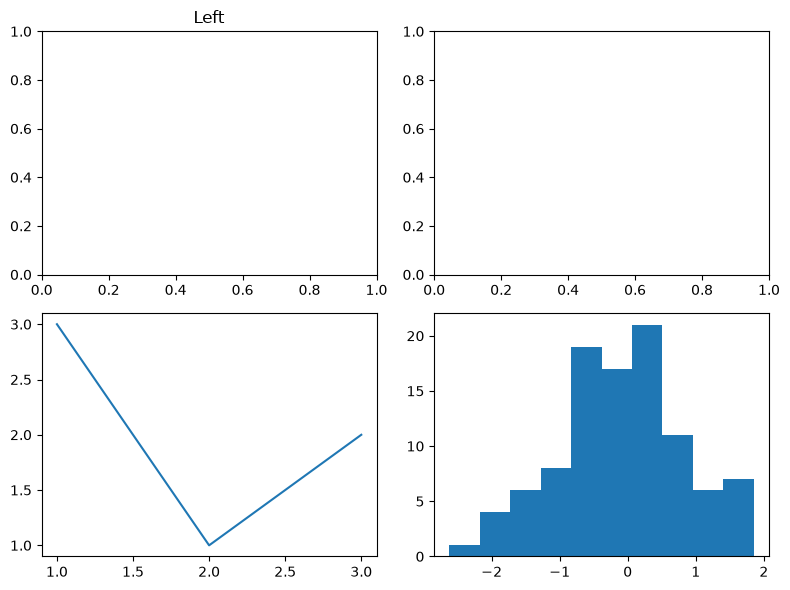

In [4]:
np.random.seed(42)
fig, ax = plt.subplots(2, 2, figsize=(8, 6))
ax[1, 0].plot([1, 2, 3], [3, 1, 2])
ax[0, 0].set_title('Left')
ax[1, 1].hist(np.random.randn(100))
plt.tight_layout()
plt.show()

### 2.d
```python
marks = np.array([[35., 80., 55.], [20., 90., 45.]])
first = marks[:, 0]
first[first < 40] = 40          # curve for display only
print(marks.mean(axis=0))
```
Intended: the original marks must remain unchanged, the curved copy is used only for display.

**ANSWER:** 
**Error:** Silent Logical Bug

**Reason:**

The expression marks[:, 0] uses basic slicing, which creates a view of the original array instead of a separate copy. Therefore, modifying first also changes the original marks array, which violates the intended requirement.

**Correction:**

Use .copy() when selecting the first column. This creates an independent copy, so changes made for display do not affect the original marks.

**Expected Output:**

Original marks column means:

```text
[27.5 85.  50. ]
```

The original marks remain unchanged.

In [5]:
marks = np.array([[35., 80., 55.],
                  [20., 90., 45.]])
first = marks[:, 0].copy()
first[first < 40] = 40
print(marks.mean(axis=0))

[27.5 85.  50. ]


### 2.e
```python
x = np.linspace(0, 1, 50)
y = np.linspace(0, 1, 30)
X, Y = np.meshgrid(x, y)
Z = np.sin(3 * x) * np.cos(2 * Y)
fig, ax = plt.subplots()
im = ax.pcolormesh(X, Y, Z)
plt.colorbar()
```
Intended: heatmap of sin(3x)cos(2y) with a working colorbar and no shape error.

**ANSWER:** 

**Error:** No runtime shape error occurs in the given code. However, the expression uses the 1D array x instead of the 2D grid X.

**Reason:**

The arrays X and Y both have shape (30, 50). The expression np.sin(3*x) has shape (50,), which NumPy broadcasts across the rows of Y. Therefore, the multiplication is valid, but using X makes the 2D grid calculation clearer and directly matches the intended mathematical expression.

**Correction:**

Replace x with X in the sine expression:

```python
Z = np.sin(3 * X) * np.cos(2 * Y)
```

Use fig.colorbar(im, ax=ax) to explicitly attach the colorbar to the heatmap.

**Expected Output:**

A heatmap representing sin(3X)cos(2Y), with a working colorbar and no shape error. The resulting Z array has shape (30, 50).

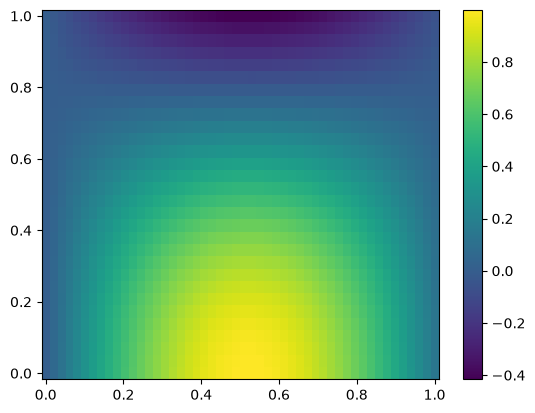

In [6]:
x = np.linspace(0, 1, 50)
y = np.linspace(0, 1, 30)
X, Y = np.meshgrid(x, y)
Z = np.sin(3 * X) * np.cos(2 * Y)
fig, ax = plt.subplots()
im = ax.pcolormesh(X, Y, Z)
fig.colorbar(im, ax=ax)
plt.show()

## Question 3: Sensor cube (18 marks)
`data/sensor_cube.npy` holds temperature readings from 6 sensors over 10 days, 24 hours per day. Axes are (day, hour, sensor). `data/sensor_meta.npz` holds `offsets` (calibration per sensor), `sensor_ids` and `days`. The logger writes -999 when a reading fails. Some other readings are physically impossible for this site (below 0 or above 60 degrees C).

**3a (3 marks)** Load both files. Print the shape, dtype and size of the cube, list the arrays stored in the npz archive and print `sensor_ids`. Report how many readings equal -999 and how many other readings are impossible. Why is -999 more dangerous than NaN if you take a mean directly?

In [7]:
cube = np.load('data/sensor_cube.npy')
meta = np.load('data/sensor_meta.npz')
print("Shape:", cube.shape)
print("Dtype:", cube.dtype)
print("Size:", cube.size)
print("Arrays in NPZ:", meta.files)
print("Sensor IDs:", meta['sensor_ids'])
failed = np.sum(cube == -999)
impossible = np.sum(((cube < 0) | (cube > 60)) & (cube != -999))
print("Failed readings:", failed)
print("Other impossible readings:", impossible)
#answer
print("-999 is dangerous because it is a numeric value, so a direct mean treats it as an extremely cold reading; NaN-aware means can ignore NaN.")

Shape: (10, 24, 6)
Dtype: float64
Size: 1440
Arrays in NPZ: ['offsets', 'sensor_ids', 'days']
Sensor IDs: ['T1' 'T2' 'T3' 'T4' 'T5' 'T6']
Failed readings: 27
Other impossible readings: 2
-999 is dangerous because it is a numeric value, so a direct mean treats it as an extremely cold reading; NaN-aware means can ignore NaN.


**3b (4 marks)** Make a float copy of the cube (not a view) where every failed or impossible reading is NaN. Prove with `np.shares_memory` that your copy is independent. Then apply calibration by adding `offsets` using broadcasting only, no loops. State the shape of the broadcast operand and why it aligns with the last axis. Write the check that the original file array is untouched.

**Explanation:** The calibration operand has shape `(6,)`. It aligns with the last dimension of the cube `(10, 24, 6)`, so the offset for each sensor is added to all days and hours for that sensor. `np.shares_memory(cube, clean_cube)` should return `False`, and comparing `cube` with `original_cube` checks that the source array was not changed.


In [8]:
original_cube = cube.copy()
clean_cube = cube.astype(float).copy()
invalid = (cube == -999) | (cube < 0) | (cube > 60)
clean_cube[invalid] = np.nan
print("Independent copy:", np.shares_memory(cube, clean_cube))
offsets = meta['offsets']
calibrated_cube = clean_cube + offsets
print("Offsets shape:", offsets.shape)
print("Calibrated cube shape:", calibrated_cube.shape)
print("Original array unchanged:", np.array_equal(cube, original_cube))

Independent copy: False
Offsets shape: (6,)
Calibrated cube shape: (10, 24, 6)
Original array unchanged: True


**3c (4 marks)** Without loops compute: (i) the mean temperature of each sensor over all days and hours, (ii) the mean daily profile of each hour averaged over days and sensors (shape 24), (iii) the hottest (day, sensor) pair using daily means. NaN must not poison the result. State the axis you used for each and why.

**Axis explanation:** `axis=(0, 1)` averages over days and hours, leaving one mean for each sensor. `axis=(0, 2)` averages over days and sensors, leaving 24 hourly means. For the hottest pair, `axis=1` averages over the 24 hours and leaves a `(10, 6)` array of daily means for each day-sensor pair.


In [9]:
# Mean temperature of each sensor over all days and hours
sensor_means = np.nanmean(calibrated_cube, axis=(0, 1))

# Mean temperature for each hour, averaged over days and sensors
hour_profile = np.nanmean(calibrated_cube, axis=(0, 2))

# First average over the 24 hours, leaving (day, sensor)
daily_sensor_means = np.nanmean(calibrated_cube, axis=1)

# Find the largest daily sensor mean and convert its position to day and sensor
max_position = np.nanargmax(daily_sensor_means)
day_index = max_position // 6
sensor_index = max_position % 6

print("Mean temperature of each sensor:", sensor_means)
print("Mean daily profile by hour:", hour_profile)
print("Daily mean array shape:", daily_sensor_means.shape)
print("Hottest day index:", day_index)
print("Hottest sensor:", meta['sensor_ids'][sensor_index])
print("Hottest daily mean:", daily_sensor_means[day_index, sensor_index])

Mean temperature of each sensor: [27.98941176 29.06385593 25.91185345 28.28786325 30.47807692 27.2178903 ]
Mean daily profile by hour: [23.28803571 22.03186441 21.31142857 21.16216667 21.426      21.87534483
 23.22283333 24.35533333 26.201      28.22431034 30.11728814 31.5837931
 33.16566667 34.13275862 34.87898305 35.1559322  35.05389831 34.11983051
 33.25050847 31.67416667 30.06827586 28.24983333 26.33864407 24.59315789]
Daily mean array shape: (10, 6)
Hottest day index: 9
Hottest sensor: T5
Hottest daily mean: 32.128750000000004


**3d (4 marks)** For sensor T3 (index 2) compute the 3-hour moving average of the hourly series for day 4 (index 3) using `np.cumsum` and slicing only, not `np.convolve`. Fill NaN in that series with the mean of the series first. Report the length of the result and explain why it is not 24.

**Explanation:** The moving-average result has length 22 because a 3-hour window can start at hours 0 through 21. The number of windows is `24 - 3 + 1 = 22`.


In [10]:
# Select sensor T3 (index 2) on day 4 (index 3)
hourly_series = calibrated_cube[3, :, 2].copy()

# Replace missing values with the mean of this 24-hour series
series_mean = np.nanmean(hourly_series)
hourly_series[np.isnan(hourly_series)] = series_mean

# Cumulative sums let us calculate each 3-hour window without convolve
cumulative = np.cumsum(hourly_series)

# First 3-hour sum is cumulative[2]; later sums subtract the value
# that falls outside the 3-hour window
moving_sum = cumulative[2:].copy()
moving_sum[1:] = cumulative[3:] - cumulative[:-3]

moving_average = moving_sum / 3

print("Filled hourly series:", hourly_series)
print("3-hour moving average:", moving_average)
print("Length of moving average:", len(moving_average))

Filled hourly series: [20.16       19.76       17.68       19.25       18.76       18.36
 21.47       21.78       22.65       25.9        27.02       28.55
 29.3        31.98       25.06478261 32.62       33.03       31.3
 31.47       28.87       25.92       26.43       23.27       20.96      ]
3-hour moving average: [19.2        18.89666667 18.56333333 18.79       19.53       20.53666667
 21.96666667 23.44333333 25.19       27.15666667 28.29       29.94333333
 28.7815942  29.88826087 30.23826087 32.31666667 31.93333333 30.54666667
 28.75333333 27.07333333 25.20666667 23.55333333]
Length of moving average: 22


**3e (3 marks)** Count the hours per day in which at least one sensor is above 35 degrees C (use `any`), and the number of days in which all sensors stay below 35 for the whole day (use `all`). Using `np.unique` with counts on the hour of each day's peak (use the sensor-averaged series), state which hour is the most common peak. Interpret in two sentences: is the sensor network behaving like a daytime heating cycle?

In [11]:
# For each hour, check whether at least one sensor is above 35 C
above_35 = calibrated_cube > 35
hours_with_hot_sensor = np.sum(np.any(above_35, axis=2), axis=1)

# A day counts only if every reading from every sensor is below 35 C
days_all_below_35 = np.sum(np.all(calibrated_cube < 35, axis=(1, 2)))

# Average the six sensors for each day and hour, then find each day's peak hour
sensor_averaged_by_hour = np.nanmean(calibrated_cube, axis=2)
peak_hours = np.nanargmax(sensor_averaged_by_hour, axis=1)

# Count how often each hour appears as the daily peak
peak_values, peak_counts = np.unique(peak_hours, return_counts=True)
most_common_position = np.argmax(peak_counts)

print("Hours per day with at least one sensor above 35:", hours_with_hot_sensor)
print("Days when all readings stay below 35:", days_all_below_35)
print("Daily peak hours:", peak_hours)
print("Peak hour counts:", list(zip(peak_values, peak_counts)))
print("Most common peak hour:", peak_values[most_common_position])

Hours per day with at least one sensor above 35: [1 3 5 7 5 7 8 7 9 9]
Days when all readings stay below 35: 0
Daily peak hours: [16 15 15 15 15 16 16 14 15 16]
Peak hour counts: [(np.int64(14), np.int64(1)), (np.int64(15), np.int64(5)), (np.int64(16), np.int64(4))]
Most common peak hour: 15


**ANSWER 3e interpretation:**

The number of hours with at least one sensor above 35°C increases from 1 hour on day 1 to 9 hours on days 9 and 10. The most common daily peak is hour 15 (3 PM), appearing on 5 days, while hour 16 appears on 4 days; this afternoon peak and the increase in hot hours are consistent with a daytime heating cycle. No day had all sensor readings below 35°C for the entire day.

## Question 4: Weather stations with Pandas (20 marks)
`data/weather_stations.csv` contains daily records for five cities. The file is messy: mixed date formats (`YYYY-MM-DD` and `DD/MM/YYYY`), temperatures stored as text such as `34.2C`, -999 as failed rain gauge value, missing humidity, pressure readings of 0 and duplicate rows.

**4a (6 marks)** Load and clean. Print `info()` before and after. Remove exact duplicates, parse both date formats into one datetime column (a plain `pd.to_datetime` call without care will silently misread days and months, check that), convert temperature to float, turn -999 into NaN, turn pressure 0 into NaN, fill missing humidity with the median humidity of the same city. Report the number of rows removed and the number of values you changed in each column. Name the cleaned frame `weather`.

In [12]:
# Load the weather data and inspect it before cleaning
weather = pd.read_csv('data/weather_stations.csv')
print("INFO BEFORE CLEANING")
weather.info()

rows_before = len(weather)
duplicate_rows = weather.duplicated().sum()
weather = weather.drop_duplicates().copy()

# Parse the two date formats separately so day and month are not swapped
slash_dates = weather['date'].str.contains('/', na=False)
parsed_dates = pd.Series(index=weather.index, dtype='datetime64[ns]')
parsed_dates.loc[slash_dates] = pd.to_datetime(weather.loc[slash_dates, 'date'], format='%d/%m/%Y')
parsed_dates.loc[~slash_dates] = pd.to_datetime(weather.loc[~slash_dates, 'date'], format='%Y-%m-%d')
weather['date'] = parsed_dates

# Remove the C character and convert temperatures to numbers
temp_text_count = weather['temp_c'].astype(str).str.contains('C', regex=False).sum()
weather['temp_c'] = weather['temp_c'].astype(str).str.replace('C', '', regex=False).astype(float)

# Replace the special failed-reading values with NaN
rain_failed_count = (weather['rain_mm'] == -999).sum()
weather.loc[weather['rain_mm'] == -999, 'rain_mm'] = np.nan

pressure_zero_count = (weather['pressure_hpa'] == 0).sum()
weather.loc[weather['pressure_hpa'] == 0, 'pressure_hpa'] = np.nan

# Fill missing humidity with the median of the same city
humidity_missing_count = weather['humidity_pct'].isna().sum()
weather['humidity_pct'] = weather.groupby('city')['humidity_pct'].transform(lambda values: values.fillna(values.median()))

print("\n===============INFO AFTER CLEANING================")
weather.info()
print("\nRows before cleaning:", rows_before)
print("Duplicate rows removed:", duplicate_rows)
print("Temperature text values converted:", temp_text_count)
print("Slash-format dates parsed:", slash_dates.sum())
print("Rain values changed from -999 to NaN:", rain_failed_count)
print("Pressure values changed from 0 to NaN:", pressure_zero_count)
print("Missing humidity values filled:", humidity_missing_count)

INFO BEFORE CLEANING
<class 'pandas.DataFrame'>
RangeIndex: 608 entries, 0 to 607
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   station_id    608 non-null    str    
 1   city          608 non-null    str    
 2   date          608 non-null    str    
 3   temp_c        608 non-null    str    
 4   humidity_pct  583 non-null    float64
 5   pressure_hpa  608 non-null    float64
 6   rain_mm       608 non-null    float64
dtypes: float64(3), str(4)
memory usage: 33.4 KB

===============INFO AFTER CLEANING================
<class 'pandas.DataFrame'>
Index: 600 entries, 0 to 607
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   station_id    600 non-null    str           
 1   city          600 non-null    str           
 2   date          600 non-null    datetime64[ns]
 3   temp_c        600 non-null    float64       
 4   humid

**4b (5 marks)** Create a month column. Build a pivot table of mean temperature by city (rows) and month (columns), rounded to 1 decimal. Find the city with the largest rise from the first month to the last month. Add a column giving each row's temperature anomaly relative to its own city's mean, using `groupby` with `transform`.

In [13]:
# Extract month number from the cleaned datetime column
weather['month'] = weather['date'].dt.month

# Mean temperature by city and month
monthly_temperature = weather.pivot_table(
    values='temp_c', index='city', columns='month', aggfunc='mean'
).round(1)

# Compare the last month with the first month for every city
temperature_rise = monthly_temperature.iloc[:, -1] - monthly_temperature.iloc[:, 0]
largest_rise_city = temperature_rise.idxmax()

# Each city's anomaly is its daily temperature minus that city's mean
weather['temp_anomaly'] = weather['temp_c'] - weather.groupby('city')['temp_c'].transform('mean')

print("=========Monthly mean temperature:===========")
print(monthly_temperature)
print("\n=========Rise from first to last month:=======")
print(temperature_rise.round(1))
print("City with the largest rise:", largest_rise_city)
print("\n==========Temperature anomaly sample:==========")
print(weather[['city', 'date', 'temp_c', 'temp_anomaly']].head())

=========Monthly mean temperature:===========
month         3     4     5     6
city                             
Islamabad  30.5  29.2  34.9  35.0
Karachi    32.6  32.0  38.3  38.5
Lahore     33.8  33.2  39.0  39.2
Peshawar   33.1  32.8  37.9  38.3
Quetta     23.4  23.3  29.9  29.6

=========Rise from first to last month:=======
city
Islamabad    4.5
Karachi      5.9
Lahore       5.4
Peshawar     5.2
Quetta       6.2
dtype: float64
City with the largest rise: Quetta

==========Temperature anomaly sample:==========
        city       date  temp_c  temp_anomaly
0    Karachi 2026-06-15    35.8      0.501667
1    Karachi 2026-04-10    32.4     -2.898333
2  Islamabad 2026-03-12    32.6      0.228333
3  Islamabad 2026-03-08    28.6     -3.771667
4     Quetta 2026-03-30    22.8     -3.711667


**4c (5 marks)** A heat spell is 3 or more consecutive days with temp above 38 in one city. Find every spell (city, start date, length). You may use NumPy on each city's sorted series, for example `diff` on a boolean array, but explain your logic in comments. If your data contains a missing calendar day for a city, say what you did about it.

In [14]:
# Find runs of at least 3 consecutive hot calendar days in each city
heat_spells = []
missing_calendar_days = {}

for city, group in weather.groupby('city'):
    group = group.sort_values('date').reset_index(drop=True)
    dates = group['date'].to_numpy()
    hot = (group['temp_c'] > 38).to_numpy()

    # Count dates absent from this city's calendar range
    full_dates = pd.date_range(group['date'].min(), group['date'].max(), freq='D')
    missing_calendar_days[city] = len(full_dates.difference(pd.DatetimeIndex(group['date'])))

    i = 0
    while i < len(group):
        if hot[i]:
            start = i
            j = i + 1

            # Continue only while the next record is hot and exactly one day later
            while (j < len(group)and hot[j]and (dates[j] - dates[j - 1]) == np.timedelta64(1, 'D')):
                j += 1

            if j - start >= 3:heat_spells.append({'city': city,'start_date': group.loc[start, 'date'],'length_days': j - start})
            i = j
        else:
            i += 1

heat_spells = pd.DataFrame(heat_spells)
print("==========Heat spells (at least 3 consecutive days above 38 C):========")
print(heat_spells.to_string(index=False))
print("\nMissing calendar days by city:", missing_calendar_days)

==========Heat spells (at least 3 consecutive days above 38 C):========
     city start_date  length_days
Islamabad 2026-06-25            3
  Karachi 2026-05-12            5
  Karachi 2026-05-20            3
  Karachi 2026-06-18           11
   Lahore 2026-05-05            4
   Lahore 2026-05-10            5
   Lahore 2026-05-16            7
   Lahore 2026-06-16            7
   Lahore 2026-06-24            5
 Peshawar 2026-05-15            6
 Peshawar 2026-06-17            4
 Peshawar 2026-06-22            7

Missing calendar days by city: {'Islamabad': 0, 'Karachi': 0, 'Lahore': 0, 'Peshawar': 0, 'Quetta': 0}


**4d (4 marks)** Compute the correlation matrix of temperature, humidity, pressure and rain. Then compute it separately for Karachi only. Interpret: which relationships are weak overall but strong inside one city, and why could pooling cities mislead you (name the effect)? Rain is mostly zero, so also state what that does to a correlation coefficient.

In [15]:
columns_for_corr = ['temp_c', 'humidity_pct', 'pressure_hpa', 'rain_mm']

overall_corr = weather[columns_for_corr].corr()
karachi_corr = weather.loc[weather['city'] == 'Karachi', columns_for_corr].corr()

print("===============Overall correlation matrix:=============")
print(overall_corr.round(3))
print("\n==============Karachi-only correlation matrix:=========")
print(karachi_corr.round(3))
print("\nZero-rain records:", (weather['rain_mm'] == 0).sum())
print("Non-missing rain records:", weather['rain_mm'].notna().sum())

===============Overall correlation matrix:=============
              temp_c  humidity_pct  pressure_hpa  rain_mm
temp_c         1.000        -0.386        -0.260    0.033
humidity_pct  -0.386         1.000         0.246    0.007
pressure_hpa  -0.260         0.246         1.000   -0.056
rain_mm        0.033         0.007        -0.056    1.000

==============Karachi-only correlation matrix:=========
              temp_c  humidity_pct  pressure_hpa  rain_mm
temp_c         1.000        -0.577        -0.208   -0.047
humidity_pct  -0.577         1.000         0.194   -0.013
pressure_hpa  -0.208         0.194         1.000    0.011
rain_mm       -0.047        -0.013         0.011    1.000

Zero-rain records: 501
Non-missing rain records: 582


**ANSWER 4d interpretation:**

The temperature-humidity relationship is stronger in Karachi (correlation about -0.577) than in the pooled data for all cities (about -0.386). Pooling cities can mix differences between city climates with relationships inside each city; this can produce a misleading result known as **Simpson's paradox**. Rainfall is zero for most records, so there is very little variation in rain and its correlation coefficients (for example, about 0.033 with temperature overall) are weak and not very informative.

## Question 5: Student performance (15 marks)
`data/student_performance.csv` has 240 students (some rows duplicated). Maximum marks are in the column names: quiz 20, assignment 20, midterm 25, final 35. Total = 100. Some midterms are the text `Absent`, some finals look like a typing slip (entered ten times too large), and some study hours are missing.

**5a (5 marks)** Clean the data. Absent counts as 0 for the total but must be kept in a separate boolean column. Fix finals that exceed 35 by the most defensible rule and say what rule you chose. Fill missing study hours with the section median. Create `total` and a `grade` column: A at 85 or more, B at 70 to 84.99, C at 55 to 69.99, D at 40 to 54.99, F below 40, using `np.where` (nested) or boolean masks, not a loop.

In [16]:
# Load data and remove exact duplicate records
students = pd.read_csv('data/student_performance.csv')
rows_before = len(students)
duplicate_students = students.duplicated().sum()
students = students.drop_duplicates().copy()

# Keep absence information before converting midterm marks to numbers
students['midterm_absent'] = students['midterm_25'] == 'Absent'
students['midterm_25'] = pd.to_numeric(students['midterm_25'], errors='coerce')
students['midterm_25'] = students['midterm_25'].fillna(0)

# The four finals above 35 are ten times too large, so divide those values by 10
finals_to_fix = students['final_35'] > 35
finals_fixed_count = finals_to_fix.sum()
students.loc[finals_to_fix, 'final_35'] = students.loc[finals_to_fix, 'final_35'] / 10

# Fill missing study hours with the median from the same section
missing_study_hours = students['study_hours_week'].isna().sum()
students['study_hours_week'] = students.groupby('section')['study_hours_week'].transform(lambda values: values.fillna(values.median()))

# Calculate total marks out of 100
students['total'] = (students['quiz_20']+ students['assignment_20']+ students['midterm_25']+ students['final_35'])

# Assign grades using the ranges in the question
students['grade'] = np.where(students['total'] >= 85, 'A',np.where(students['total'] >= 70, 'B',
        np.where(students['total'] >= 55, 'C',np.where(students['total'] >= 40, 'D', 'F'))))

print("Rows before cleaning:", rows_before)
print("Duplicate rows removed:", duplicate_students)
print("Final marks corrected by dividing by 10:", finals_fixed_count)
print("Missing study hours filled:", missing_study_hours)
print("\nAbsent midterm count:", students['midterm_absent'].sum())
print("Cleaned student data sample:")
print(students.head())

Rows before cleaning: 243
Duplicate rows removed: 3
Final marks corrected by dividing by 10: 4
Missing study hours filled: 7

Absent midterm count: 9
Cleaned student data sample:
  student_id section  attendance_pct  study_hours_week  quiz_20  \
0      S1000       A            81.0               7.4     11.7   
1      S1001       C            71.0              10.1     11.8   
2      S1002       B            95.0              13.7     11.0   
3      S1003       B            55.0               8.8      7.0   
4      S1004       A            70.0               7.8      9.8   

   assignment_20  midterm_25  final_35  midterm_absent  total grade  
0           12.4         8.6      26.2           False   58.9     C  
1           15.3        14.0      24.5           False   65.6     C  
2           20.0        16.8      25.4           False   73.2     B  
3           11.6        13.4      13.0           False   45.0     D  
4            9.0        10.9      21.9           False   51.6     D 

**5b (5 marks)** Per section report: number of students, mean total, std of total, pass percentage (not F), and the student_id with the highest total. Then list students with attendance below 75 who still scored a B or better. Use a single boolean mask.

In [17]:
# Summary values for each section
section_summary = students.groupby('section').agg(
    number_of_students=('student_id', 'count'),mean_total=('total', 'mean'),std_total=('total', 'std'),
    pass_percentage=('grade', lambda grades: (grades != 'F').mean() * 100)
)

# Find the student with the highest total in each section
top_positions = students.groupby('section')['total'].idxmax()
top_students = students.loc[top_positions, ['section', 'student_id', 'total']]

# One Boolean mask: attendance below 75 and grade B or A
low_attendance_mask = ((students['attendance_pct'] < 75)& (students['grade'].isin(['A', 'B'])))
low_attendance_good_grades = students.loc[low_attendance_mask,['student_id', 'section', 'attendance_pct', 'total', 'grade']]

print("================Section summary:===================")
print(section_summary.round(2))
print("\n===========Highest-total student in each section:============")
print(top_students.to_string(index=False))
print("\n==========Students with attendance below 75 and grade B or better:==========")
print(low_attendance_good_grades.to_string(index=False))

================Section summary:===================
         number_of_students  mean_total  std_total  pass_percentage
section                                                            
A                        71       63.09      14.69            91.55
B                        64       62.95      13.46            96.88
C                        49       65.07      12.46            97.96
D                        56       64.49      15.13            92.86

===========Highest-total student in each section:============
section student_id  total
      A      S1074   89.9
      B      S1082   87.9
      C      S1017   99.6
      D      S1055   95.6

==========Students with attendance below 75 and grade B or better:==========
student_id section  attendance_pct  total grade
     S1005       A            60.0   73.6     B
     S1009       D            65.0   77.2     B
     S1066       A            71.0   77.3     B
     S1089       B            74.0   81.3     B
     S1092       A           

**5c (5 marks)** Compute the correlation of study hours with total and with final. Fit a straight line of total on study hours with `np.polyfit` (degree 1) and report slope and intercept. Interpret the slope in plain words with units. Then compare mean total of absent-midterm students and everyone else and state whether this proves absence causes low marks. Mention at least one confounder visible in the data.

In [18]:
# Correlation between weekly study hours and marks
study_total_corr = students['study_hours_week'].corr(students['total'])
study_final_corr = students['study_hours_week'].corr(students['final_35'])

# Fit total = slope * study_hours + intercept
slope, intercept = np.polyfit(students['study_hours_week'], students['total'], 1)

# Compare students who were absent in the midterm with the others
absent_mean = students.loc[students['midterm_absent'], 'total'].mean()
present_mean = students.loc[~students['midterm_absent'], 'total'].mean()

print("Correlation: study hours with total:", study_total_corr)
print("Correlation: study hours with final:", study_final_corr)
print("Line slope (marks per extra weekly study hour):", slope)
print("Line intercept:", intercept)
print("Mean total for absent-midterm students:", absent_mean)
print("Mean total for other students:", present_mean)
print("Mean attendance for absent-midterm students:",students.loc[students['midterm_absent'], 'attendance_pct'].mean())
print("Mean attendance for other students:",students.loc[~students['midterm_absent'], 'attendance_pct'].mean())

Correlation: study hours with total: 0.7766228955402087
Correlation: study hours with final: 0.6806658662093116
Line slope (marks per extra weekly study hour): 2.171242586535731
Line intercept: 37.723172566132504
Mean total for absent-midterm students: 50.355555555555554
Mean total for other students: 64.304329004329
Mean attendance for absent-midterm students: 71.44444444444444
Mean attendance for other students: 76.34632034632034


**ANSWER 5c interpretation:**

Study hours have a positive correlation with total marks (about 0.777) and final marks (about 0.681). The fitted slope is about 2.17, meaning the fitted line predicts approximately 2.17 additional total marks for each extra weekly study hour; this is an association, not a guarantee for an individual student. Students absent from the midterm have a lower mean total (about 50.36) than other students (about 64.30), but this does not prove absence causes low marks. Attendance is a visible possible confounder: the absent-midterm group has mean attendance about 71.44%, compared with about 76.35% for the other students.

## Question 6: Dashboard (15 marks)
Build one figure, `figsize=(14, 9)`, using `GridSpec` with 3 rows and 3 columns and constrained layout or `tight_layout`. Use your cleaned `weather`, `students` (from Q5) and the calibrated sensor cube. Required panels:
1. (top row, spans 2 columns) Daily mean temperature of each city as lines with different line styles, a shared legend outside the axes and a marked heat spell using `fill_between` or `axvspan`. Add a twin y-axis with mean humidity of one city (a different colour, with colour matched tick labels).
2. (top right) Horizontal bar chart of mean total per section with `errorbar` style whiskers showing std. Print the bar values as text.
3. (middle row, left) Histogram of student totals with bins every 5 marks from 0 to 100, a vertical dashed line at the mean, and `ax.annotate` with an arrow pointing to the tallest bin. Use data coordinates for the arrow target and axes coordinates for the text.
4. (middle row, middle) Scatter of study hours vs total coloured by attendance, with colorbar and the polyfit line from Q5c.
5. (middle right) Step plot of the hourly sensor-average profile (24 hours), y-axis limits chosen by you and justified in a comment.
6. (bottom row, spans all columns) `imshow` heatmap of the day by hour mean sensor temperature (10 x 24) with a diverging colormap centred on the overall mean using `vmin`/`vmax`, tick labels showing real day numbers, and an inset axes (`inset_axes` or `fig.add_axes`) showing the hour with the maximum anomaly as a small bar chart over days.
Mark split: layout 3, panels 1 to 2 4, panels 3 to 5 4, panel 6 3, labels/titles/legend quality 1. Save as PNG at 200 dpi and as PDF.

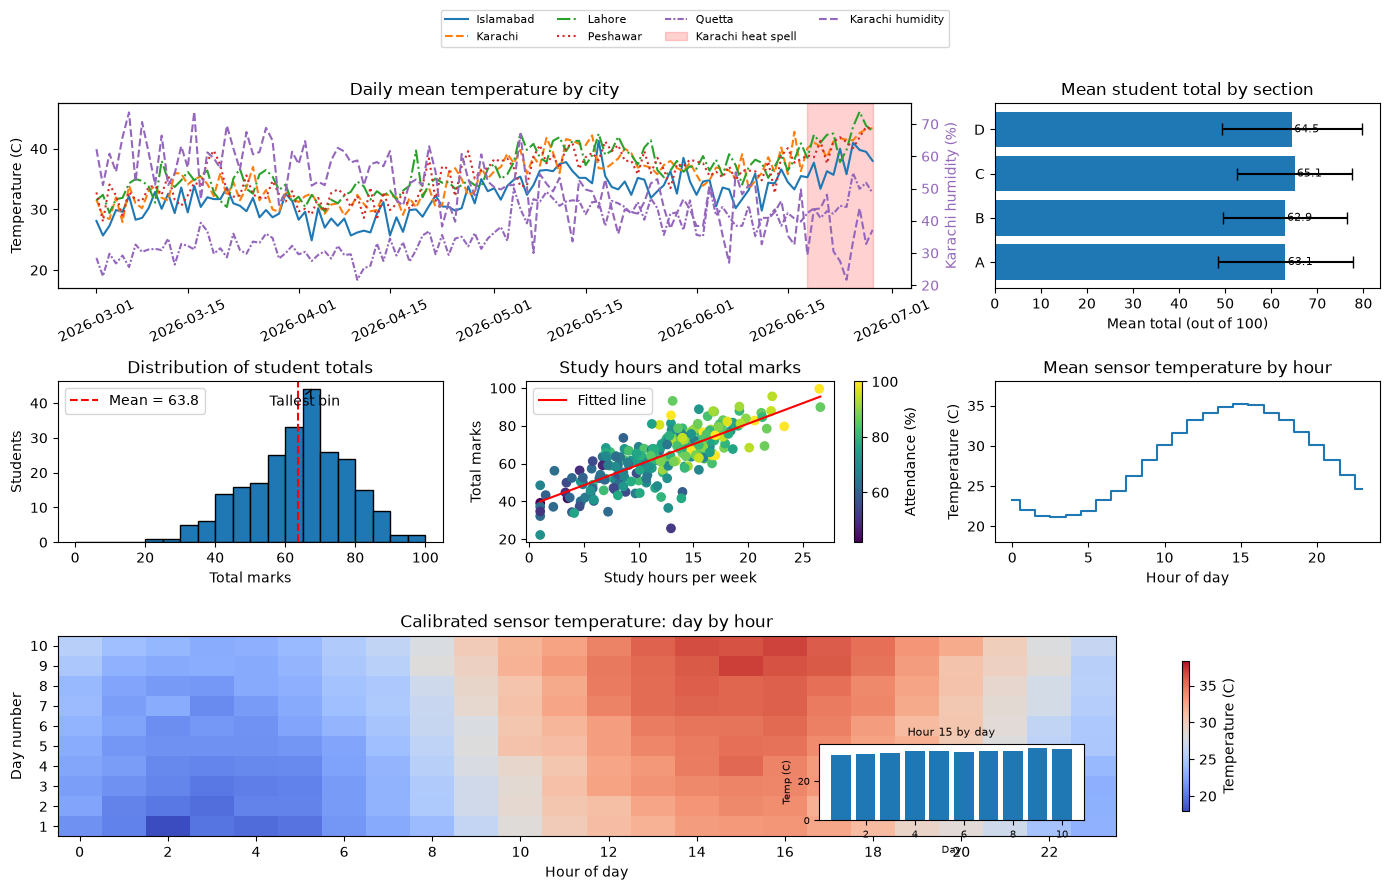

In [25]:
import os

# Prepare the daily city temperature lines and Karachi humidity line
daily_city = weather.groupby(['date', 'city'])['temp_c'].mean().reset_index()
karachi_humidity = (weather[weather['city'] == 'Karachi'].groupby('date')['humidity_pct'].mean())

fig = plt.figure(figsize=(14, 9))
grid = fig.add_gridspec(3, 3, height_ratios=[1.15, 1.0, 1.25])

# Panel 1: city temperatures across two columns
ax1 = fig.add_subplot(grid[0, 0:2])
line_styles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]
cities = sorted(weather['city'].unique())

for city, style in zip(cities, line_styles):
    city_data = daily_city[daily_city['city'] == city]
    ax1.plot(city_data['date'], city_data['temp_c'],linestyle=style, label=city)

# Mark the Karachi heat spell found in Q4(c): 18 to 28 June 2026
ax1.axvspan(pd.Timestamp('2026-06-18'), pd.Timestamp('2026-06-28'),alpha=0.18, color='red', label='Karachi heat spell')
ax1.set_title('Daily mean temperature by city')
ax1.set_ylabel('Temperature (C)')
ax1.tick_params(axis='x', rotation=25)

# Add Karachi humidity on a second y-axis
ax1b = ax1.twinx()
humidity_line, = ax1b.plot(karachi_humidity.index, karachi_humidity.values,
    color='tab:purple', linestyle='--', label='Karachi humidity')
ax1b.set_ylabel('Karachi humidity (%)', color=humidity_line.get_color())
ax1b.tick_params(axis='y', labelcolor=humidity_line.get_color())

# One shared legend outside the axes
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax1b.get_legend_handles_labels()
fig.legend(handles1 + handles2, labels1 + labels2,
           loc='upper center', bbox_to_anchor=(0.5, 0.99),
           ncol=4, fontsize=8)

# Panel 2: mean total by section with standard-deviation whiskers
ax2 = fig.add_subplot(grid[0, 2])
section_means = students.groupby('section')['total'].mean()
section_stds = students.groupby('section')['total'].std()
bars = ax2.barh(section_means.index, section_means.values,
                xerr=section_stds.values, capsize=4)
ax2.set_title('Mean student total by section')
ax2.set_xlabel('Mean total (out of 100)')
for bar, value in zip(bars, section_means.values):
    ax2.text(value + 0.5, bar.get_y() + bar.get_height() / 2,
             f'{value:.1f}', va='center', fontsize=8)

# Panel 3: student total histogram, 5-mark bins
ax3 = fig.add_subplot(grid[1, 0])
bin_edges = np.arange(0, 105, 5)
counts, edges, patches = ax3.hist(students['total'], bins=bin_edges, edgecolor='black')
mean_total = students['total'].mean()
ax3.axvline(mean_total, linestyle='--', color='red', label=f'Mean = {mean_total:.1f}')
tallest_bin = np.argmax(counts)
bin_center = (edges[tallest_bin] + edges[tallest_bin + 1]) / 2
ax3.annotate('Tallest bin',xy=(bin_center, counts[tallest_bin]), xycoords='data',
             xytext=(0.55, 0.85), textcoords='axes fraction',arrowprops={'arrowstyle': '->'})
ax3.set_title('Distribution of student totals')
ax3.set_xlabel('Total marks')
ax3.set_ylabel('Students')
ax3.legend()

# Panel 4: study hours against total, coloured by attendance
ax4 = fig.add_subplot(grid[1, 1])
scatter = ax4.scatter(students['study_hours_week'], students['total'],c=students['attendance_pct'])
x_line = np.linspace(students['study_hours_week'].min(),students['study_hours_week'].max(), 100)
ax4.plot(x_line, slope * x_line + intercept, color='red', label='Fitted line')
fig.colorbar(scatter, ax=ax4, label='Attendance (%)')
ax4.set_title('Study hours and total marks')
ax4.set_xlabel('Study hours per week')
ax4.set_ylabel('Total marks')
ax4.legend()

# Panel 5: 24-hour calibrated sensor profile
ax5 = fig.add_subplot(grid[1, 2])
hours = np.arange(24)
ax5.step(hours, hour_profile, where='mid')
ax5.set_title('Mean sensor temperature by hour')
ax5.set_xlabel('Hour of day')
ax5.set_ylabel('Temperature (C)')
# The observed hourly profile is about 21 to 35 C, so these limits show it clearly.
ax5.set_ylim(18, 38)

# Panel 6: day-by-hour heatmap averaged over the six calibrated sensors
ax6 = fig.add_subplot(grid[2, :])
daily_hour_mean = np.nanmean(calibrated_cube, axis=2)
overall_sensor_mean = np.nanmean(daily_hour_mean)
largest_deviation = np.nanmax(np.abs(daily_hour_mean - overall_sensor_mean))
image = ax6.imshow(daily_hour_mean, aspect='auto', origin='lower',cmap='coolwarm',
vmin=overall_sensor_mean - largest_deviation,vmax=overall_sensor_mean + largest_deviation)
ax6.set_title('Calibrated sensor temperature: day by hour')
ax6.set_xlabel('Hour of day')
ax6.set_ylabel('Day number')
ax6.set_xticks(np.arange(0, 24, 2))
ax6.set_yticks(np.arange(10))
ax6.set_yticklabels(meta['days'])
fig.colorbar(image, ax=ax6, label='Temperature (C)', shrink=0.75)

# Find the hour whose average is farthest from the overall mean
hour_anomalies = np.nanmean(daily_hour_mean, axis=0) - overall_sensor_mean
max_anomaly_hour = np.argmax(np.abs(hour_anomalies))
inset = ax6.inset_axes([0.72, 0.08, 0.25, 0.38])
inset.bar(meta['days'], daily_hour_mean[:, max_anomaly_hour])
inset.set_title(f'Hour {max_anomaly_hour} by day', fontsize=8)
inset.set_xlabel('Day', fontsize=7)
inset.set_ylabel('Temp (C)', fontsize=7)
inset.tick_params(labelsize=7)

os.makedirs('outputs', exist_ok=True)
fig.tight_layout(rect=[0, 0, 1, 0.92])
fig.savefig('outputs/dashboard.png', dpi=200, bbox_inches='tight')
fig.savefig('outputs/dashboard.pdf', bbox_inches='tight')
plt.show()

**ANSWER 6 (4 sentences):**

The most important operational finding is the 11-day Karachi heat spell from 18 to 28 June 2026, when daily mean temperature stayed above 38°C. The calibrated sensor profile also reaches its highest hourly average at about 35.16°C around hour 15 (3 PM), so afternoon monitoring is important. The bottom heatmap shows the day-by-hour pattern, while the inset compares the daily readings at the hour with the largest average anomaly. The top-left panel could mislead a reader because it uses two y-axes for temperature and humidity, and the different scales can make the lines appear more closely or weakly related than they really are.

## Question 7: Surfaces and animation (10 marks)
Let f(x, y) = sin(r) / r with r = sqrt(x^2 + y^2) on x, y in [-10, 10].

**7a interpretation:** The code counts 6,280 grid points below -0.1. These negative values form the outer concentric trough/ring regions around the central positive peak in the sinc-shaped surface.


**7a (4 marks)** Build the grid with `meshgrid` of 201 points per axis. Handle r = 0 correctly (the limit is 1; a plain division gives NaN, show you saw it and fixed it with `np.where`). Draw side by side: `pcolormesh` with a diverging colormap and symmetric `vmin`/`vmax`, and `contourf` with `contour` lines labelled using `clabel`. Add colorbars. Count (with Boolean sums) how many grid points have f below -0.1 and say what visual feature that corresponds to.

NaN values before fixing r = 0: 1
NaN values after fixing: 0
Grid points where f is below -0.1: 6280


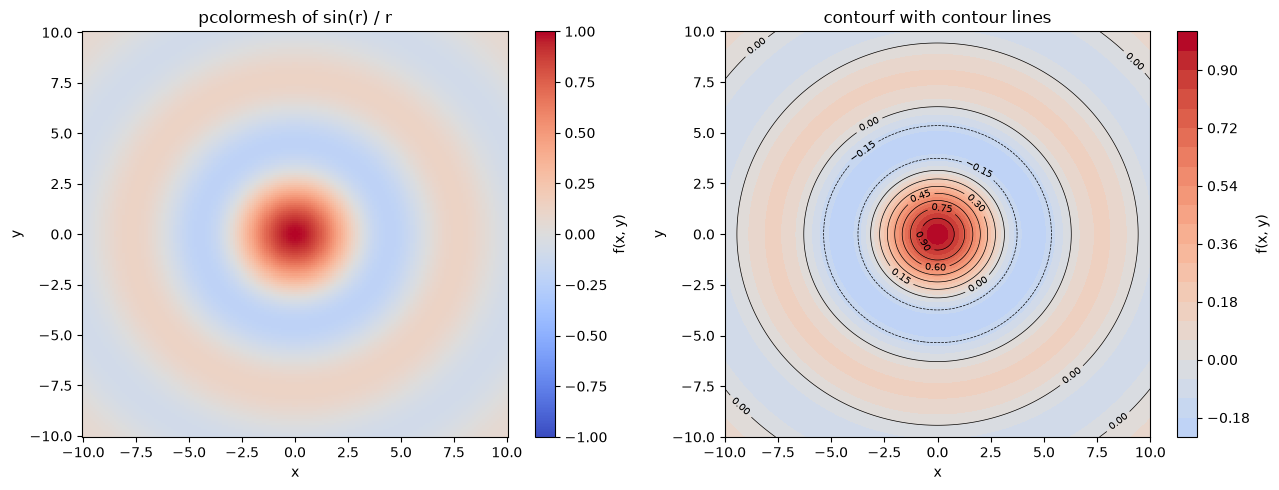

In [23]:
# Build a 201 by 201 coordinate grid
x_values = np.linspace(-10, 10, 201)
y_values = np.linspace(-10, 10, 201)
X, Y = np.meshgrid(x_values, y_values)
r = np.sqrt(X ** 2 + Y ** 2)

# First calculate sin(r) / r directly; it produces NaN at r = 0
with np.errstate(divide='ignore', invalid='ignore'):
    f_raw = np.sin(r) / r
print("NaN values before fixing r = 0:", np.isnan(f_raw).sum())

# The limit at the origin is 1, so replace that one NaN using np.where
F = np.where(r == 0, 1, f_raw)
print("NaN values after fixing:", np.isnan(F).sum())

# Count the grid points below -0.1
below_count = np.sum(F < -0.1)
print("Grid points where f is below -0.1:", below_count)

# Use symmetric colour limits around zero
colour_limit = np.max(np.abs(F))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

mesh = axes[0].pcolormesh(X, Y, F, cmap='coolwarm',vmin=-colour_limit, vmax=colour_limit, shading='auto')
axes[0].set_title('pcolormesh of sin(r) / r')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
fig.colorbar(mesh, ax=axes[0], label='f(x, y)')

filled = axes[1].contourf(X, Y, F, levels=20, cmap='coolwarm',vmin=-colour_limit, vmax=colour_limit)
contours = axes[1].contour(X, Y, F, levels=10, colors='black', linewidths=0.5)
axes[1].clabel(contours, inline=True, fontsize=7)
axes[1].set_title('contourf with contour lines')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
fig.colorbar(filled, ax=axes[1], label='f(x, y)')

plt.tight_layout()
plt.show()

**7b (3 marks)** Make a 3D surface with `plot_surface` using `rstride=5, cstride=5`, then a `plot_wireframe` of the same data, and add a contour projection onto the floor (`zdir="z"`, with offset below the minimum). Use `view_init(elev=35, azim=-60)`. Explain what changes if rstride and cstride are set to 1 and why.

**7b explanation:** Setting `rstride` and `cstride` to 1 draws a much denser surface mesh using every grid row and column. The surface looks smoother and more detailed, but it takes more time and resources to render.

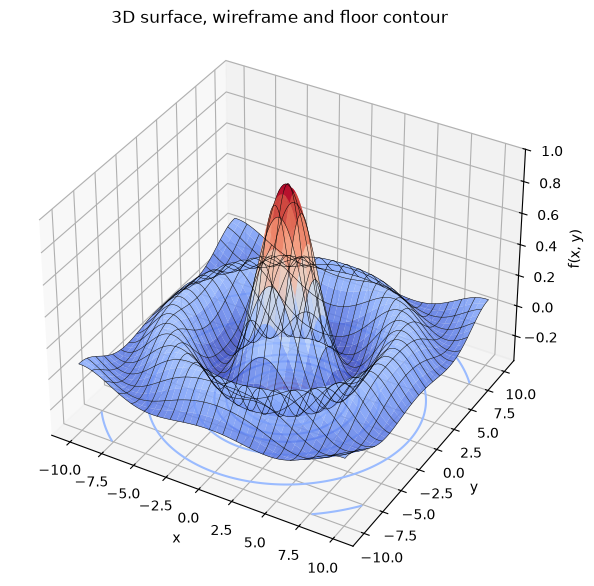

In [24]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Draw the surface using the requested stride values
ax.plot_surface(X, Y, F, rstride=5, cstride=5, cmap='coolwarm',edgecolor='none', alpha=0.85)

# Add a wireframe of the same function
ax.plot_wireframe(X, Y, F, rstride=10, cstride=10,color='black', linewidth=0.35)

# Project contour lines onto a floor below the minimum value
floor_level = np.min(F) - 0.15
ax.contour(X, Y, F, zdir='z', offset=floor_level, cmap='coolwarm')

ax.set_title('3D surface, wireframe and floor contour')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('f(x, y)')
ax.set_zlim(floor_level, np.max(F))
ax.view_init(elev=35, azim=-60)

plt.show()

**7c (3 marks)** Animate the travelling wave sin(r - 0.3 t)/r along the line y = 0 using `FuncAnimation` with 60 frames, `interval=50` and `blit=True`. Your update function must return the artist(s). Save as `wave.gif` with `PillowWriter`. Do not use `plt.show()` blocking calls. Say in a comment why blit needs the update function to return a tuple.

In [ ]:
# Use the line y = 0, so r = |x|
x_wave = np.linspace(-10, 10, 201)
r_wave = np.abs(x_wave)

fig, ax = plt.subplots(figsize=(9, 4))

# At t = 0, the limit at x = 0 is 1
initial_wave = np.sin(r_wave) / np.where(r_wave == 0, 1, r_wave)
initial_wave[r_wave == 0] = 1
line, = ax.plot(x_wave, initial_wave)

ax.set_title('Travelling wave: sin(r - 0.3t) / r')
ax.set_xlabel('x (y = 0)')
ax.set_ylabel('Wave value')
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.grid(True)

def update(frame):
    t = frame * 0.1

    # The expression is undefined at r = 0 for t > 0, so leave a gap there.
    with np.errstate(divide='ignore', invalid='ignore'):
        wave_values = np.sin(r_wave - 0.3 * t) / r_wave

    if frame == 0:
        wave_values[r_wave == 0] = 1
    else:
        wave_values[r_wave == 0] = np.nan

    line.set_ydata(wave_values)

    # blit=True needs update() to return a tuple of the artists that changed.
    return (line,)

animation = FuncAnimation(fig, update, frames=60, interval=50, blit=True)

os.makedirs('outputs', exist_ok=True)
animation.save('outputs/wave.gif', writer=PillowWriter(fps=20))
plt.close(fig)
print("Saved animation to outputs/wave.gif")

Saved animation to outputs/wave.gif


## Final checklist
- Restart and Run All works.
- All ANSWER cells are filled.
- `outputs/dashboard.png`, `outputs/dashboard.pdf` and `outputs/wave.gif` are created by the notebook.
- Code is pushed to GitHub as described in the submission instructions.